# Лабораторная работа №4. Методы анализа нестационарных сигналов

**Вариант:** группа — 2, ПК — 4: $N = 6$, $L = N \bmod 3 = 0$.

| Параметр | Значение |
|---|---|
| Сигнал | последовательность ЛЧМ-импульсов |
| Начальная частота $F_н$ | $1000 + 20N = 1120$ кГц |
| Конечная частота $F_к$ | $1400 + 20N = 1520$ кГц (девиация 400 кГц) |
| Длительность чипа | 40 мкс, из них импульс $0{,}96\cdot 40 = 38{,}4$ мкс и пауза («молчание») 1,6 мкс |
| Число импульсов | 8 (интервал 320 мкс) |
| Частота дискретизации | 8 МГц |

Длительность импульса взята из шаблона (40 мкс). Длительность $t_и = 6$ нс из ЛР3 меньше одного периода несущей ~1 МГц, поэтому для ЛЧМ-импульсов она не подходит.

**Назначение частотно-временного анализа.** Спектр Фурье всего сигнала показывает, *какие* частоты присутствуют, но не *когда*. У нестационарных сигналов (ЛЧМ, ППРЧ, импульсные последовательности) спектральный состав меняется во времени. Спектрограмма (оконное преобразование Фурье) и вейвлет-преобразование показывают распределение энергии сигнала на плоскости «время — частота». По ним можно определить закон изменения частоты, моменты начала и конца импульсов и частотные каналы.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as dsp
import pywt
from toolbox import get_chirp_pulse

plt.rcParams.update({'figure.figsize': (13, 4.5), 'figure.dpi': 110,
                     'axes.grid': True, 'grid.alpha': 0.3})

N = 6
f_d = 8e6                      # частота дискретизации, Гц
t_d = 1 / f_d
t_chip = 40e-6                 # длительность чипа, с
t_impulse = 0.96 * t_chip      # длительность импульса (остальное — пауза)
f_start = (1000 + 20 * N) * 1e3
f_stop = (1400 + 20 * N) * 1e3
n_chips = 8
print(f'Fн = {f_start/1e3:.0f} кГц, Fк = {f_stop/1e3:.0f} кГц, '
      f'пауза = {(t_chip - t_impulse)*1e6:.1f} мкс = {(t_chip - t_impulse)/t_d:.1f} отсчёта')

Fн = 1120 кГц, Fк = 1520 кГц, пауза = 1.6 мкс = 12.8 отсчёта


## 1. Формирование сигнала

Мгновенная частота ЛЧМ-импульса линейно растёт от $F_н$ до $F_к$ за время $t_и$:
$$x(t) = \sin\!\left(2\pi\left(F_н t + \frac{F_к - F_н}{2t_и}\,t^2\right)\right),\qquad f(t) = F_н + \frac{F_к-F_н}{t_и}\,t,\qquad 0\le t < t_и.$$
Используется функция `get_chirp_pulse` из `toolbox.py`. Каждый чип состоит из импульса длительностью $t_и$ и паузы. Чипы следуют друг за другом.

Отсчётов в чипе: 320, всего: 2560


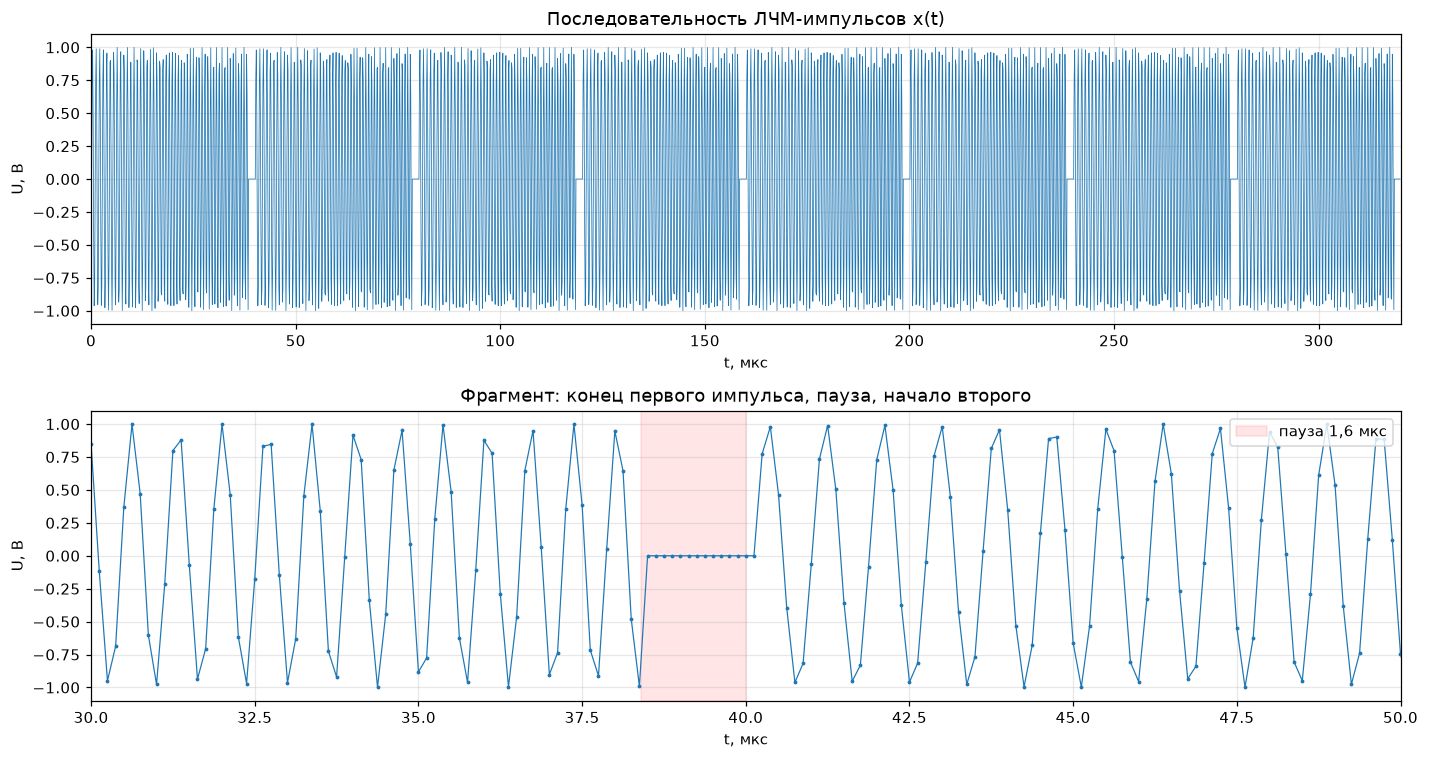

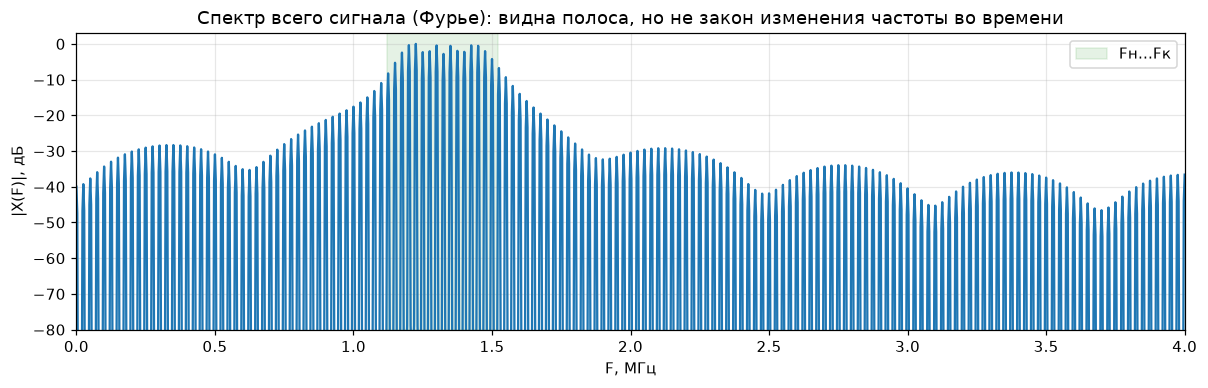

In [2]:
# +t_d/2 защищает от округления вниз в math.floor внутри toolbox
chip = np.array(get_chirp_pulse(t_d, t_chip + t_d/2, t_impulse + t_d/2, f_start, f_stop - f_start))
signal_out = np.tile(chip, n_chips)
n_total = signal_out.size
t_ax_us = np.arange(n_total) * t_d * 1e6

# Мгновенная частота (для наложения на спектрограммы)
t_in_chip = np.arange(chip.size) * t_d
f_inst = np.where(t_in_chip < t_impulse, f_start + (f_stop - f_start) * t_in_chip / t_impulse, np.nan)
f_inst = np.tile(f_inst, n_chips) / 1e6
print(f'Отсчётов в чипе: {chip.size}, всего: {n_total}')

fig, axs = plt.subplots(2, 1, figsize=(13, 7))
axs[0].plot(t_ax_us, signal_out, lw=0.5)
axs[0].set(title='Последовательность ЛЧМ-импульсов x(t)', xlabel='t, мкс', ylabel='U, В', xlim=(0, n_chips * 40))
axs[1].plot(t_ax_us, signal_out, '.-', lw=0.8, ms=3)
axs[1].axvspan(t_impulse * 1e6, t_chip * 1e6, color='r', alpha=0.1, label='пауза 1,6 мкс')
axs[1].set(title='Фрагмент: конец первого импульса, пауза, начало второго', xlabel='t, мкс', ylabel='U, В', xlim=(30, 50))
axs[1].legend(loc='upper right')
plt.tight_layout()

f_sp = np.fft.rfftfreq(n_total, t_d) / 1e6
X = np.abs(np.fft.rfft(signal_out * np.hamming(n_total)))
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(f_sp, 20 * np.log10(X / X.max() + 1e-12))
ax.axvspan(f_start / 1e6, f_stop / 1e6, color='g', alpha=0.1, label='Fн…Fк')
ax.set(title='Спектр всего сигнала (Фурье): видна полоса, но не закон изменения частоты во времени',
       xlabel='F, МГц', ylabel='|X(F)|, дБ', xlim=(0, 4), ylim=(-80, 3))
ax.legend();

## 2. Спектрограммы

Спектрограмма — квадрат модуля оконного преобразования Фурье:
$$S(t, f) = \left|\sum_k x_k\, w_{k - t}\, e^{-j2\pi f k\Delta t}\right|^2.$$
Чем короче окно $w$ (длительность $T_w$), тем лучше разрешение по времени, но хуже по частоте: $\Delta f \approx 1/T_w$ (принцип неопределённости $\Delta t\cdot\Delta f \gtrsim 1$).

Выбор длительности окна:
- **короткое окно** — 8 отсчётов (1 мкс) меньше паузы 1,6 мкс, поэтому на спектрограмме видны интервалы молчания; разрешение по частоте около 1 МГц;
- **длинное окно** — 80 отсчётов (10 мкс): разрешение по частоте около 100–130 кГц, что намного меньше девиации 400 кГц, поэтому виден наклон ЛЧМ. За время окна частота уходит на $400\cdot10/38{,}4 \approx 104$ кГц, то есть «размазывание» из-за ЛЧМ сравнимо с разрешением. Такая длительность близка к оптимальной для ЛЧМ: $T_w \approx 1/\sqrt{\dot f} \approx 10$ мкс.

Шаг смещения окна: `noverlap = W − 1` — шаг в 1 отсчёт, `noverlap = 0` — шаг, равный длине окна.

In [3]:
def plot_spectrogram(x, nperseg, window, noverlap, title, ax, nfft=512, overlay=True, vmin=-70):
    f, t, S = dsp.spectrogram(x, fs=f_d, window=window, nperseg=nperseg, noverlap=noverlap,
                              nfft=max(nfft, nperseg), detrend=False, mode='psd')
    S_db = 10 * np.log10(S / S.max() + 1e-15)
    im = ax.pcolormesh(t * 1e6, f / 1e6, S_db, shading='nearest', cmap='viridis', vmin=vmin, vmax=0)
    if overlay:
        ax.plot(t_ax_us, f_inst, 'w--', lw=0.8, alpha=0.7, label='f(t) — мгновенная частота')
        ax.legend(loc='upper right', fontsize=8)
    ax.set(title=title, xlabel='t, мкс', ylabel='F, МГц', ylim=(0, 3))
    ax.grid(False)
    plt.colorbar(im, ax=ax, label='дБ')
    return t.size


W_short, W_long = 8, 80

### 2.1 Влияние типа окна: прямоугольное и Хэмминга (одинаковая длина 80 отсчётов, шаг 1 отсчёт)

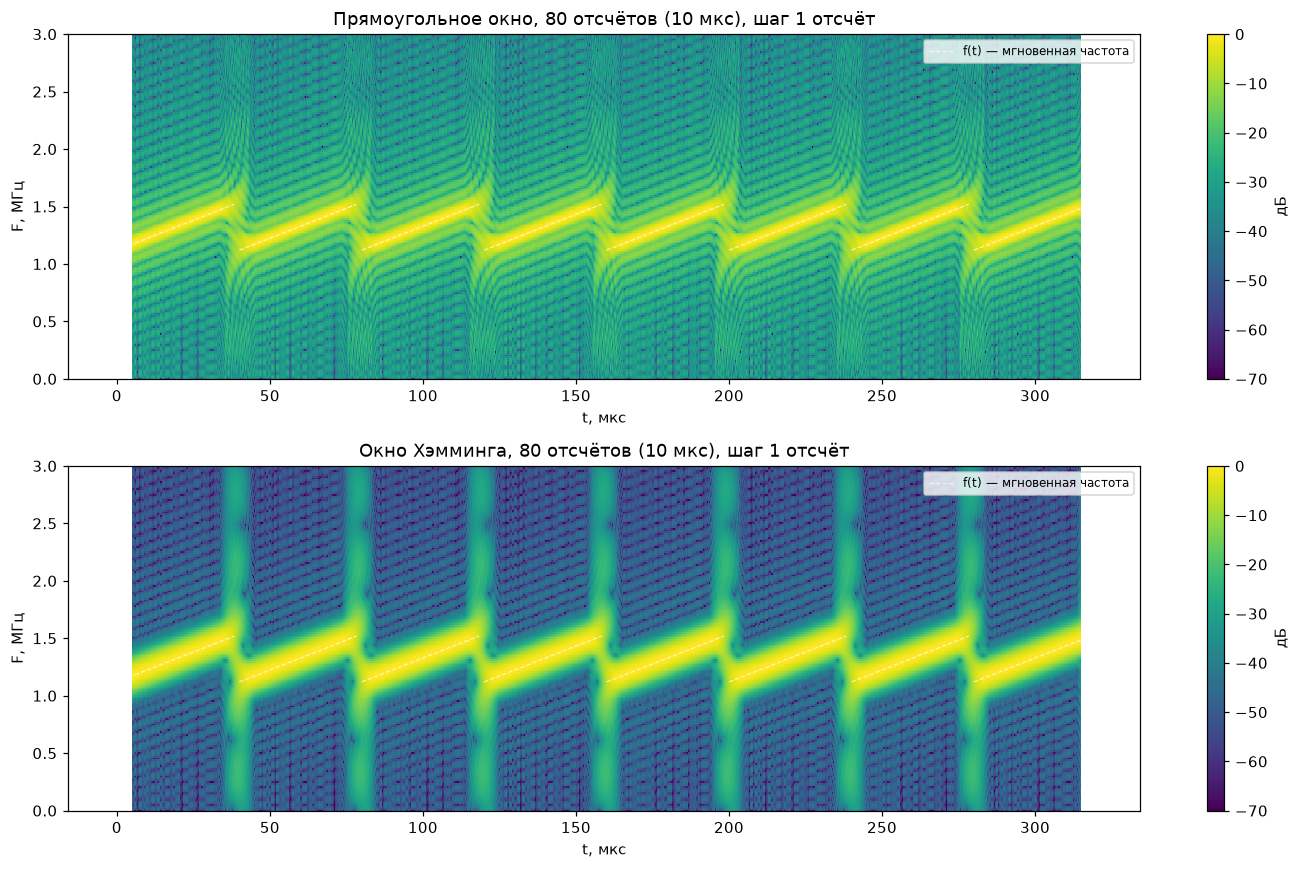

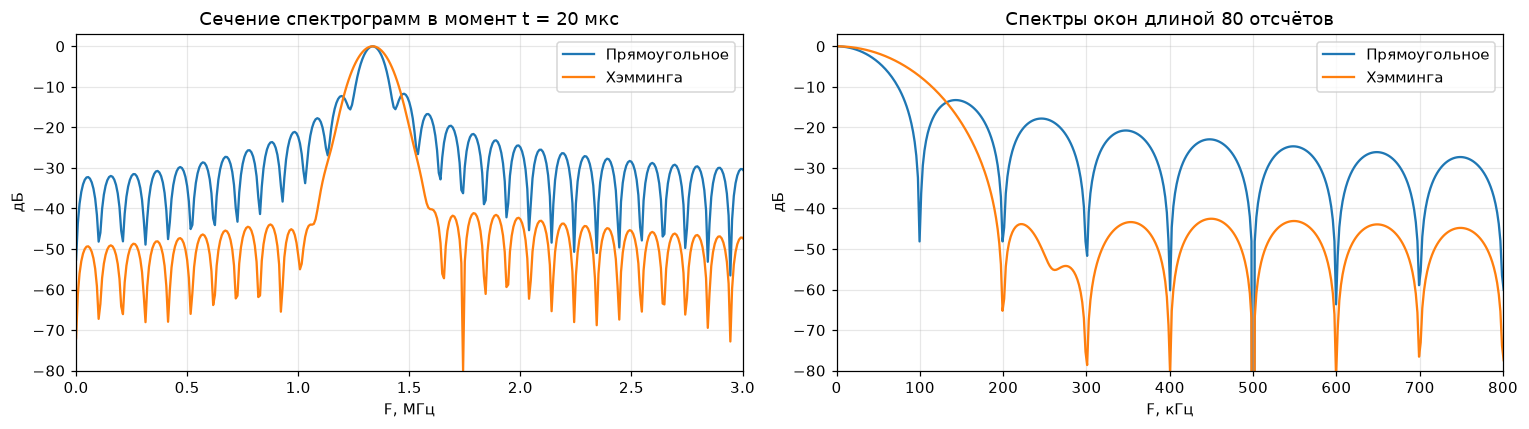

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(13, 8))
plot_spectrogram(signal_out, W_long, 'boxcar', W_long - 1,
                 f'Прямоугольное окно, {W_long} отсчётов ({W_long*t_d*1e6:.0f} мкс), шаг 1 отсчёт', axs[0])
plot_spectrogram(signal_out, W_long, 'hamming', W_long - 1,
                 f'Окно Хэмминга, {W_long} отсчётов ({W_long*t_d*1e6:.0f} мкс), шаг 1 отсчёт', axs[1])
plt.tight_layout()

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for win, nm in [('boxcar', 'Прямоугольное'), ('hamming', 'Хэмминга')]:
    f, t, S = dsp.spectrogram(signal_out, fs=f_d, window=win, nperseg=W_long, noverlap=W_long - 1, nfft=1024, detrend=False)
    i = np.argmin(np.abs(t - 20e-6))
    axs[0].plot(f / 1e6, 10 * np.log10(S[:, i] / S[:, i].max()), label=nm)
    w = dsp.get_window(win, W_long)
    Wf = np.abs(np.fft.rfft(w, 4096)); fw = np.fft.rfftfreq(4096, t_d) / 1e3
    axs[1].plot(fw, 20 * np.log10(Wf / Wf.max() + 1e-12), label=nm)
axs[0].set(title='Сечение спектрограмм в момент t = 20 мкс', xlabel='F, МГц', ylabel='дБ', xlim=(0, 3), ylim=(-80, 3))
axs[1].set(title=f'Спектры окон длиной {W_long} отсчётов', xlabel='F, кГц', ylabel='дБ', xlim=(0, 800), ylim=(-80, 3))
for ax in axs:
    ax.legend()
plt.tight_layout()

### 2.2 Влияние длительности окна и шага смещения (окно Хэмминга)

Число временных отсчётов спектрограммы: шаг 1 — 2481, шаг 80 — 32


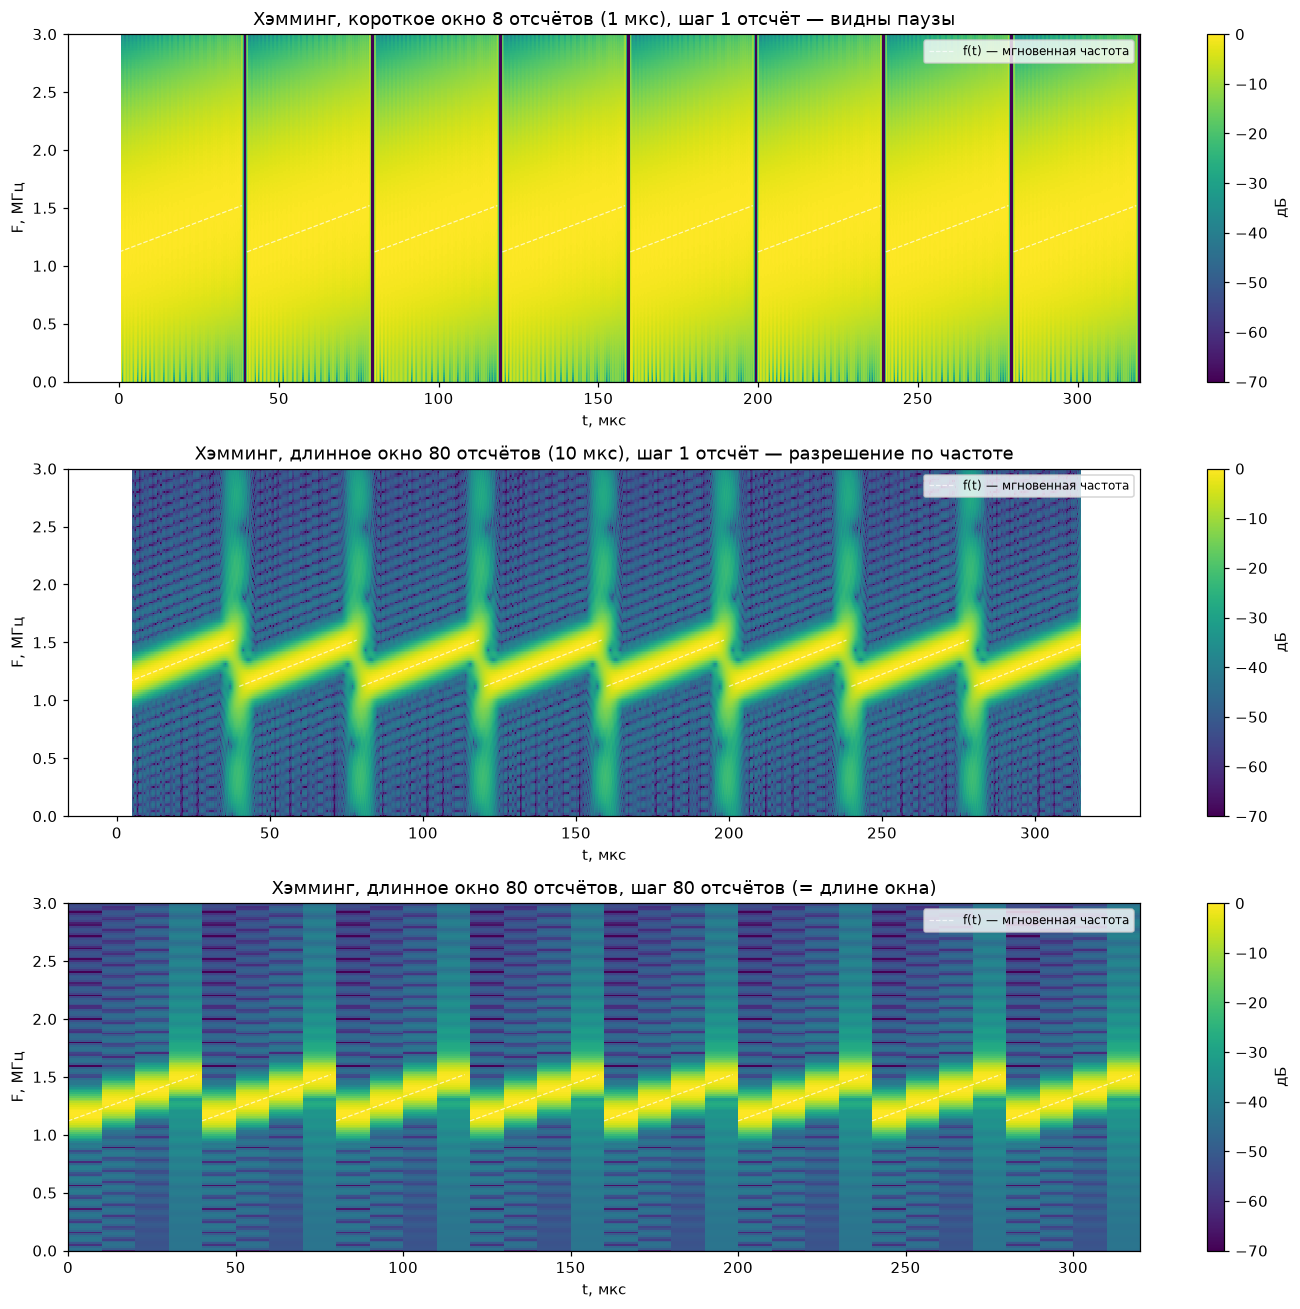

In [5]:
fig, axs = plt.subplots(3, 1, figsize=(13, 12))
plot_spectrogram(signal_out, W_short, 'hamming', W_short - 1,
                 f'Хэмминг, короткое окно {W_short} отсчётов ({W_short*t_d*1e6:.0f} мкс), шаг 1 отсчёт — видны паузы', axs[0])
n1 = plot_spectrogram(signal_out, W_long, 'hamming', W_long - 1,
                 f'Хэмминг, длинное окно {W_long} отсчётов ({W_long*t_d*1e6:.0f} мкс), шаг 1 отсчёт — разрешение по частоте', axs[1])
n2 = plot_spectrogram(signal_out, W_long, 'hamming', 0,
                 f'Хэмминг, длинное окно {W_long} отсчётов, шаг {W_long} отсчётов (= длине окна)', axs[2])
plt.tight_layout()
print(f'Число временных отсчётов спектрограммы: шаг 1 — {n1}, шаг {W_long} — {n2}')

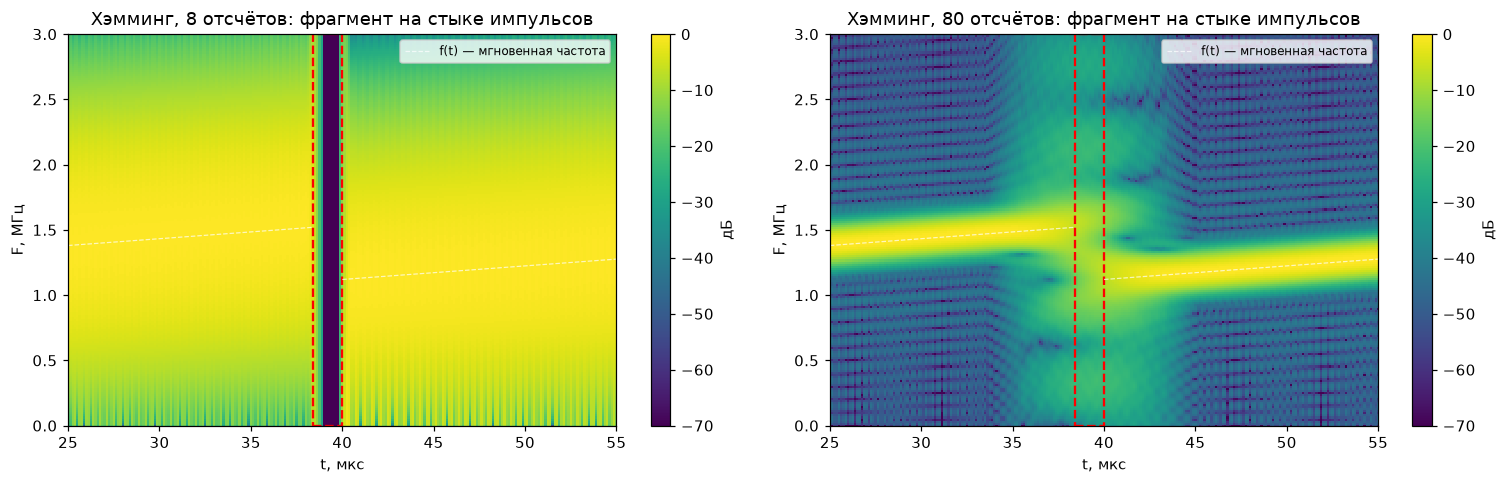

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, W in zip(axs, [W_short, W_long]):
    plot_spectrogram(signal_out, W, 'hamming', W - 1, f'Хэмминг, {W} отсчётов: фрагмент на стыке импульсов', ax)
    ax.set_xlim(25, 55)
    ax.axvspan(t_impulse * 1e6, t_chip * 1e6, ec='r', fc='none', lw=1.5, ls='--')
plt.tight_layout()

## 3. Непрерывное вейвлет-преобразование

$$W(a, b) = \frac{1}{\sqrt{a}}\int x(t)\,\psi^*\!\left(\frac{t - b}{a}\right)dt,$$
где $a$ — масштаб, $b$ — сдвиг. Масштаб связан с частотой как $f = f_c/(a\,\Delta t)$, где $f_c$ — центральная частота вейвлета.
В отличие от спектрограммы, длительность базисной функции пропорциональна масштабу. Поэтому на низких частотах выше разрешение по частоте, а на высоких — по времени.

Используются комплексный вейвлет Морле `cmor1.5-1.0` (по модулю коэффициентов видна огибающая энергии) и действительный Морле `morl`, как в шаблоне.

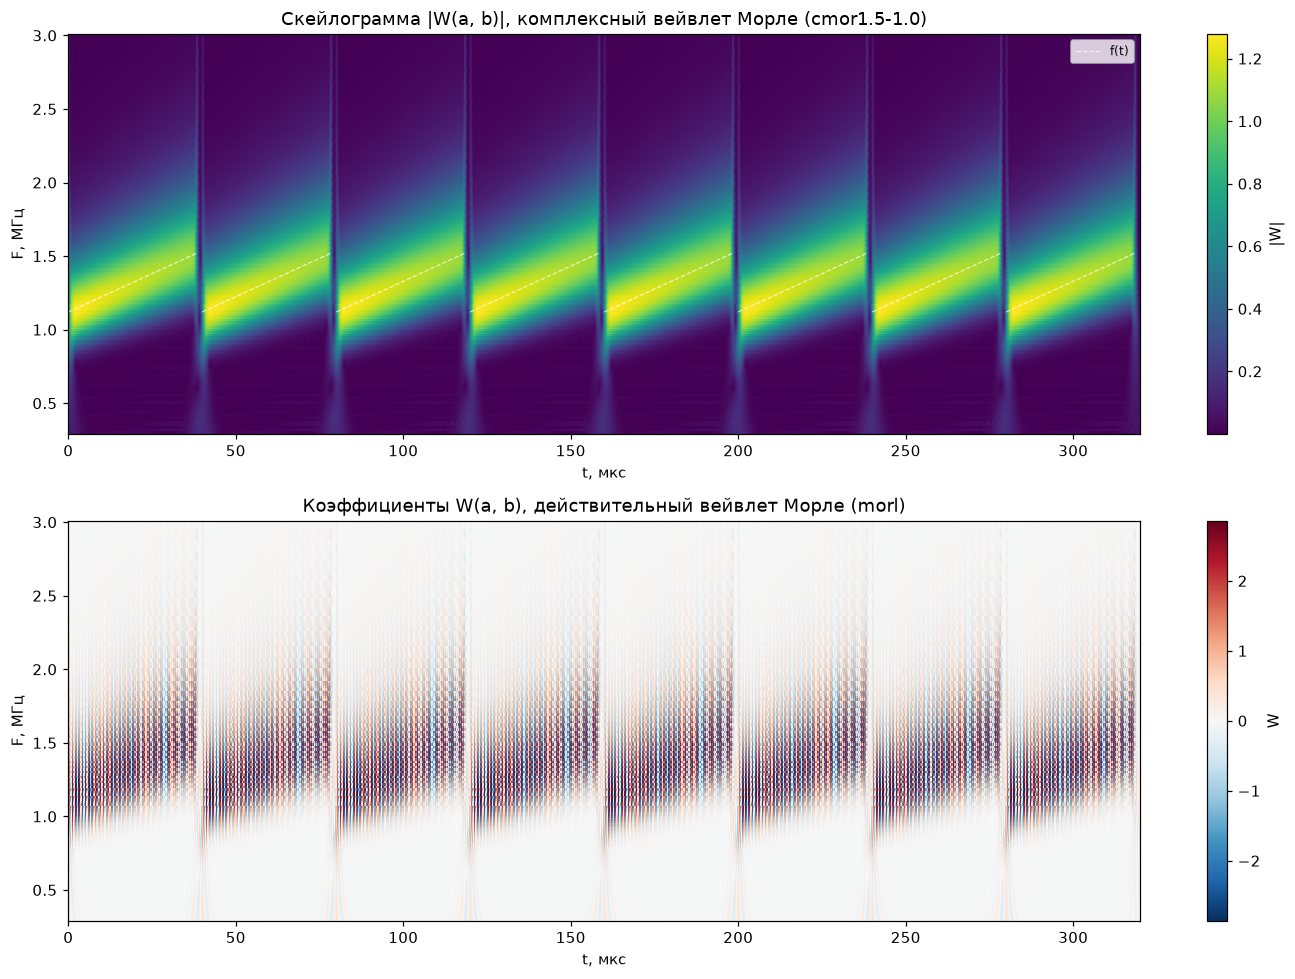

In [7]:
freqs_hz = np.linspace(0.3e6, 3e6, 160)
wav_c = 'cmor1.5-1.0'
scales_c = pywt.central_frequency(wav_c) / (freqs_hz * t_d)
coef_c, f_c = pywt.cwt(signal_out, scales_c, wav_c, sampling_period=t_d)

scales_r = pywt.central_frequency('morl') / (freqs_hz * t_d)
coef_r, f_r = pywt.cwt(signal_out, scales_r, 'morl', sampling_period=t_d)

fig, axs = plt.subplots(2, 1, figsize=(13, 9))
im = axs[0].pcolormesh(t_ax_us, f_c / 1e6, np.abs(coef_c), shading='auto', cmap='viridis')
axs[0].plot(t_ax_us, f_inst, 'w--', lw=0.8, alpha=0.7, label='f(t)')
axs[0].legend(loc='upper right', fontsize=8)
axs[0].set(title=f'Скейлограмма |W(a, b)|, комплексный вейвлет Морле ({wav_c})', xlabel='t, мкс', ylabel='F, МГц')
plt.colorbar(im, ax=axs[0], label='|W|')
lim = np.abs(coef_r).max()
im = axs[1].pcolormesh(t_ax_us, f_r / 1e6, coef_r, shading='auto', cmap='RdBu_r', vmin=-lim, vmax=lim)
axs[1].set(title='Коэффициенты W(a, b), действительный вейвлет Морле (morl)', xlabel='t, мкс', ylabel='F, МГц')
plt.colorbar(im, ax=axs[1], label='W')
for ax in axs:
    ax.grid(False)
plt.tight_layout()

## Выводы

1. **Назначение.** Спектрограммы и вейвлет-преобразование показывают, как спектральный состав сигнала меняется во времени. Спектр Фурье всего сигнала даёт только полосу 1,12–1,52 МГц. На спектрограмме видна линейная зависимость $f(t)$ внутри каждого импульса (наклонные линии от 1,12 до 1,52 МГц), периодичность 40 мкс и паузы между импульсами.
2. **Тип окна.** При одинаковой длине (80 отсчётов) прямоугольное окно даёт более узкий главный лепесток, но высокий уровень боковых лепестков (−13 дБ). Энергия «растекается» по частоте, на спектрограмме видны полосы вокруг линии ЛЧМ, и динамический диапазон мал. Окно Хэмминга расширяет главный лепесток примерно в 2 раза, но снижает боковые лепестки до −43 дБ. Линия ЛЧМ получается «чистой», фон ниже на десятки дБ.
3. **Длительность окна.** Короткое окно (8 отсчётов = 1 мкс) меньше паузы 1,6 мкс, поэтому интервалы молчания видны как разрывы на спектрограмме. Однако разрешение по частоте около 1 МГц, и полоса сигнала размыта почти на всю ось: наклон ЛЧМ не различим. Длинное окно (80 отсчётов = 10 мкс) даёт разрешение около 100 кГц, и закон изменения частоты виден отчётливо. Но окно длиннее паузы, поэтому паузы «замазываются»: в момент стыка в окно попадают конец одного импульса (1,52 МГц) и начало следующего (1,12 МГц), и видны обе частоты сразу. Это проявление принципа неопределённости $\Delta t\cdot\Delta f\gtrsim1$: одновременно получить высокое разрешение и по времени, и по частоте нельзя.
4. **Шаг смещения окна.** Шаг 1 отсчёт даёт гладкую спектрограмму с максимальной детализацией по времени (2481 столбец), но требует больших вычислений. Шаг, равный длине окна (окна не перекрываются), даёт только 32 столбца: спектрограмма «ступенчатая», и момент начала импульса определяется с точностью до длительности окна. Разрешающую способность шаг не меняет: она задаётся длиной окна. Шаг определяет только частоту, с которой берутся отсчёты по времени.
5. **Вейвлет-преобразование.** На скейлограмме тоже видна линейная зависимость частоты от времени. Разрешение по частоте и времени зависит от частоты: на нижних частотах базисная функция длиннее, поэтому выше разрешение по частоте, а на верхних — по времени. На стыках импульсов видны широкополосные выбросы, связанные со скачком частоты и фазы. Модуль коэффициентов комплексного вейвлета Морле показывает огибающую энергии, а действительный Морле — ещё и фазу колебаний (чередование знака коэффициентов).